In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

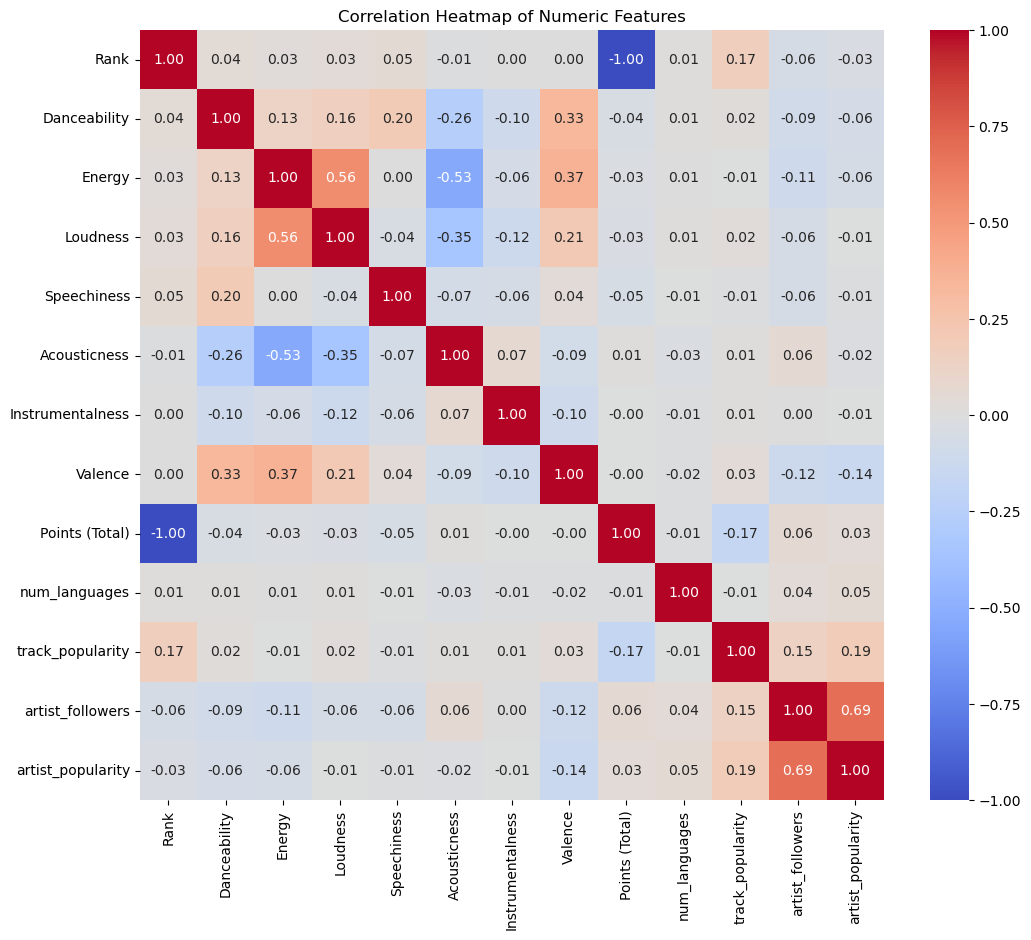

In [2]:
df = pd.read_csv("data/additional_features.csv")

# Assuming your DataFrame is df
numeric_cols = df.select_dtypes(include=['number']).columns
df_numeric = df[numeric_cols]

corr = df_numeric.corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


In [6]:
# Fill missing genres and split into lists
df['artist_genres_list'] = df['artist_genres'].fillna("").apply(lambda x: x.split(", "))

# Explode so each genre is a separate row
df_exploded = df.explode('artist_genres_list')

genre_counts = df_exploded['artist_genres_list'].value_counts().reset_index()
genre_counts.columns = ['genre', 'song_count']


genre_counts.to_csv("data/genre_counts.csv", index=False)


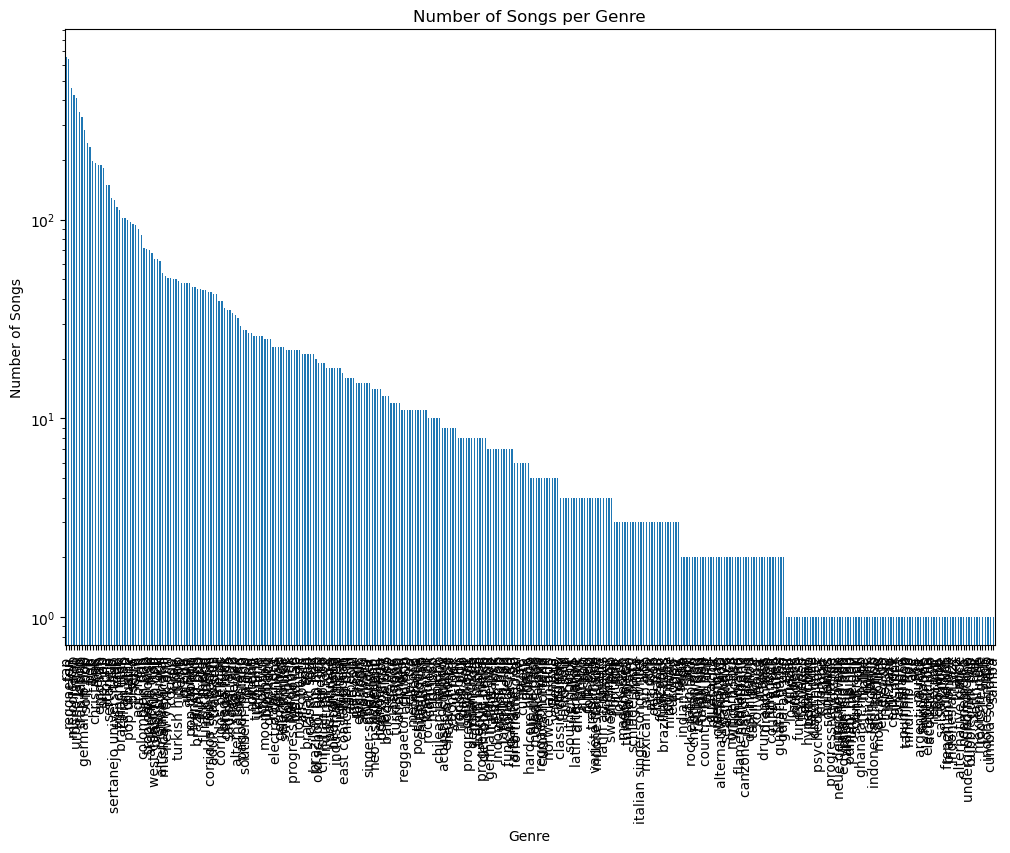

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Fill missing genres and split into lists
df['artist_genres_list'] = df['artist_genres'].fillna("").apply(lambda x: x.split(", "))

# Explode so each genre is a separate row
df_exploded = df.explode('artist_genres_list')

# Filter out empty strings
df_exploded = df_exploded[df_exploded['artist_genres_list'] != ""]

genre_counts = df_exploded['artist_genres_list'].value_counts()

plt.figure(figsize=(12,8))
genre_counts.plot(kind='bar', logy=True)
plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of Songs")
plt.title("Number of Songs per Genre")
plt.show()


In [10]:
df = pd.read_csv("data/data.csv")
#delete the columns:followers, genres and popularity
df.drop(columns=["followers", "genres", "popularity"], inplace=True)
output_path = "data/data.csv"
df.to_csv(output_path, index=False)
print(f"✅ Done! Saved enriched data to {output_path}")

✅ Done! Saved enriched data to data/data.csv


In [11]:
#get a unique list of genres
df = pd.read_csv("data/data.csv")
unique_genres = set()
for genres in df['artist_genres'].dropna():
    for genre in genres.split(", "):
        unique_genres.add(genre)

print(f"Total unique genres: {len(unique_genres)}")
print(sorted(unique_genres))

#save the list of unique genres as a dataset
unique_genres_df = pd.DataFrame(sorted(unique_genres), columns=['genre'])
unique_genres_df.to_csv("data/unique_genres.csv", index=False)


Total unique genres: 346
['acoustic country', 'acoustic pop', 'adult standards', 'afro r&b', 'afro soul', 'afrobeat', 'afrobeats', 'afropiano', 'afropop', 'afroswing', 'agronejo', 'alternative dance', 'alternative hip hop', 'alternative metal', 'alternative r&b', 'alternative rock', 'alté', 'amapiano', 'anime', 'aor', 'arabesk', 'arabic hip hop', 'argentine rock', 'argentine trap', 'arrocha', 'art pop', 'art rock', 'axé', 'azonto', 'bacardi', 'bachata', 'banda', 'baroque pop', 'bedroom pop', 'bhangra', 'big band', 'big room', 'blues rock', 'bolero', 'bollywood', 'boom bap', 'brazilian bass', 'brazilian funk', 'brazilian hip hop', 'brazilian phonk', 'brazilian pop', 'brazilian trap', 'brega', 'brega funk', 'britpop', 'brooklyn drill', 'bubblegum pop', 'canzone napoletana', 'ccm', 'celtic', 'celtic punk', 'celtic rock', 'chanson', 'chicago drill', 'chilean mambo', 'chilean trap', 'christian', 'christian hip hop', 'christian pop', 'christmas', 'classic country', 'classic rock', 'classic s

In [44]:
df = pd.read_csv("data/data.csv")

def simplify_genres(genres, keywords):
    """
    Takes a string or list of genres and replaces any genre containing a keyword
    with that keyword, leaving other genres unchanged.
    
    Parameters:
    - genres: str, list, or NaN
    - keywords: str or list of str
    """
    if pd.isna(genres):
        return genres

    # Ensure keywords is a list
    if isinstance(keywords, str):
        keywords = [keywords]

    # If it's a string, split into a list
    if isinstance(genres, str):
        genre_list = [g.strip() for g in genres.split(',')]
    elif isinstance(genres, list):
        genre_list = genres
    else:
        return genres  # in case of unexpected format

    # Replace any genre containing a keyword (case-insensitive) with the keyword
    cleaned = []
    for g in genre_list:
        replaced = False
        for kw in keywords:
            if kw.lower() in g.lower():
                cleaned.append(kw)
                replaced = True
                break
        if not replaced:
            cleaned.append(g)

    # Remove duplicates but preserve order
    cleaned = list(dict.fromkeys(cleaned))
    return ', '.join(cleaned)


# Replace genres containing 'pop' with 'pop'
df['artist_genres'] = df['artist_genres'].apply(lambda x: simplify_genres(x, 'rock'))
df['artist_genres'] = df['artist_genres'].apply(lambda x: simplify_genres(x, 'pop'))
df['artist_genres'] = df['artist_genres'].apply(lambda x: simplify_genres(x, 'hip hop'))

#print the artist_genres column
df['artist_genres'].head(100).dropna()

#export this
df.to_csv("data/data.csv", index=False)

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform

# ===============================
# 1. Load Data
# ===============================
data = pd.read_csv("data/data.csv")


# ===============================
# 2. One-Hot Encoding and Cleanup
# ===============================
# Encode 'explicit' column
explicit_dummies = pd.get_dummies(data['explicit'], prefix='explicit')
data = pd.concat([data, explicit_dummies], axis=1)
data.drop(columns=['explicit'], inplace=True)

# Encode nationality, continent, and detected languages
nationality_dummies = pd.get_dummies(data['Nationality'], prefix='Nationality')
continent_dummies = pd.get_dummies(data['Continent'], prefix='Continent')
detected_languages_dummies = pd.get_dummies(data['detected_languages'], prefix='detected_languages')

data = pd.concat([data, nationality_dummies, continent_dummies, detected_languages_dummies], axis=1)
data.drop(columns=['Nationality', 'Continent', 'detected_languages'], inplace=True)

# Optional: write preprocessed data to file
# data.to_csv("data/features-annotated-artistless-with-lyrics-and-languages-onehot.csv", index=False)

# Extract the updated column list
data_cols = data.columns.tolist()

# ===============================
# 3. Expand Artists (if needed)
# ===============================
data_exploded = data.assign(
    Primary_Artists_List=data['Primary Artists'].str.split(', ')
).explode('Primary_Artists_List')

songs_by_artist = data_exploded.groupby('Primary_Artists_List')

artists = os.path.join(os.getcwd(), 'data', 'artists.csv')

# ===============================
# 4. Define Song Features
# ===============================
song_features = [
    'Danceability', 'Energy', 'Speechiness', 'Acousticness', 'Instrumentalness',
    'Valence', 'Points (Total)', 'track_popularity', 'artist_followers',
    'artist_popularity', 'Loudness'
]

# Add all one-hot encoded columns automatically
one_hot_features = [col for col in data.columns if (
    col.startswith('explicit_') or
    col.startswith('Nationality_') or
    col.startswith('Continent_') or
    col.startswith('detected_languages_')
)]
song_features.extend(one_hot_features)

# ===============================
# 5. PCA Analysis
# ===============================


In [46]:
X = data[song_features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

data['PCA1'] = X_pca[:, 0]
data['PCA2'] = X_pca[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_)

# ===============================
# 6. Aggregate Songs by Genre
# ===============================
# Handle multiple genres separated by commas
if data['artist_genres'].str.contains(',').any():
    data_exploded_genres = data.assign(artist_genres=data['artist_genres'].str.split(', '))
    data_exploded_genres = data_exploded_genres.explode('artist_genres')
else:
    data_exploded_genres = data.copy()

# Average PCA positions per genre
genre_pca = data_exploded_genres.groupby('artist_genres')[['PCA1', 'PCA2']].mean().reset_index()

X_genre = genre_pca[['PCA1', 'PCA2']].values
genre_names = genre_pca['artist_genres'].values

Explained variance ratio: [0.03480759 0.02489941]


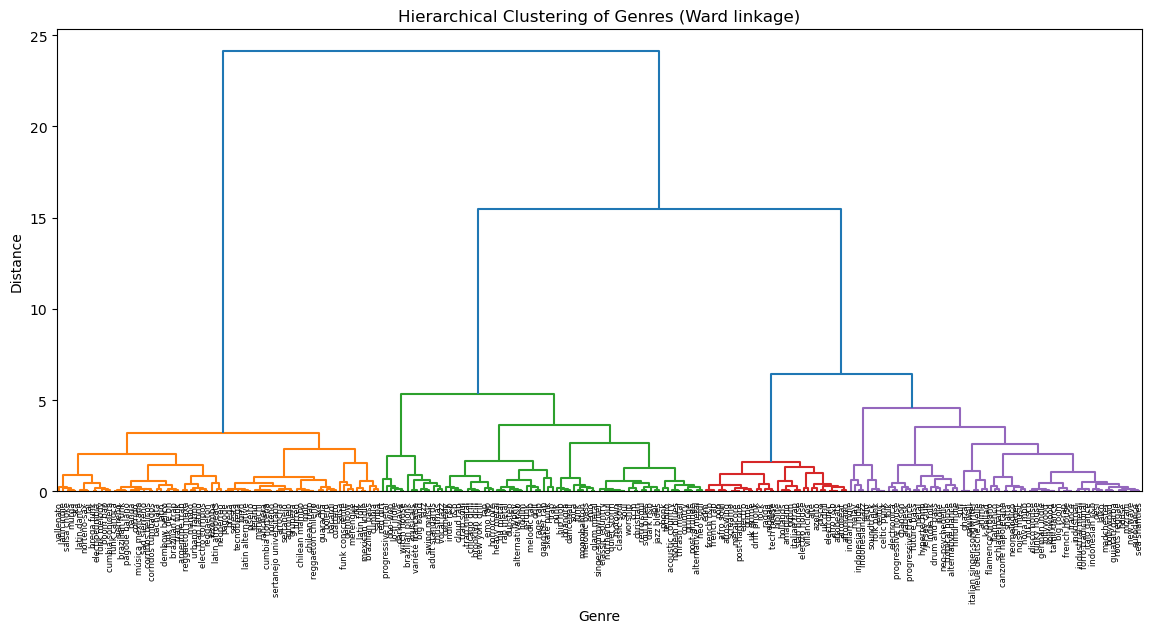

In [47]:
# ===============================
# 7. Hierarchical Clustering
# ===============================
scaler2 = StandardScaler()
X_genre_scaled = scaler2.fit_transform(X_genre)

Z = linkage(X_genre_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, labels=genre_names, leaf_rotation=90, leaf_font_size=6, color_threshold=6)
plt.title("Hierarchical Clustering of Genres (Ward linkage)")
plt.xlabel("Genre")
plt.ylabel("Distance")
plt.show()

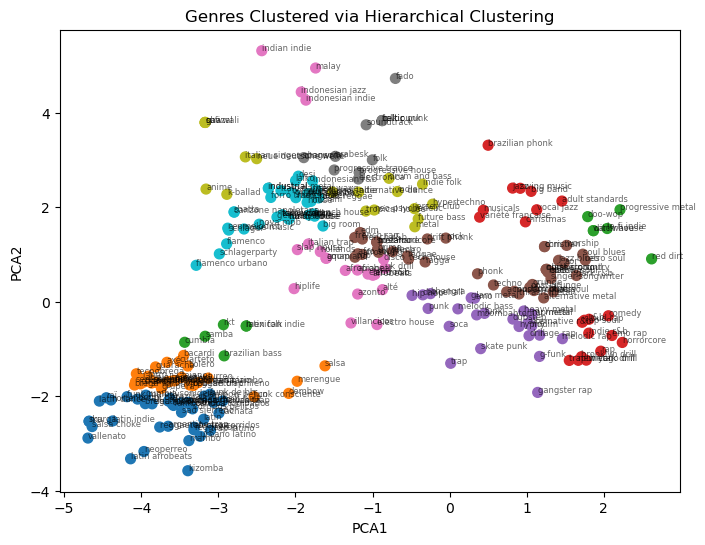

In [53]:
# 8. Choose Number of Clusters
# ===============================
num_clusters = 20  # adjust manually or optimize below
clusters = fcluster(Z, num_clusters, criterion='maxclust')
genre_pca['cluster'] = clusters

# ===============================
# 9. Visualize Clusters in PCA Space
# ===============================
plt.figure(figsize=(8, 6))
plt.scatter(genre_pca['PCA1'], genre_pca['PCA2'], c=genre_pca['cluster'], cmap='tab10', s=50)
for i, txt in enumerate(genre_pca['artist_genres']):
    plt.annotate(txt, (genre_pca['PCA1'][i], genre_pca['PCA2'][i]), fontsize=6, alpha=0.6)
plt.title("Genres Clustered via Hierarchical Clustering")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.show()

In [54]:
# ===============================
# 10. Inspect Cluster Composition
# ===============================
for c in sorted(genre_pca['cluster'].unique()):
    print(f"\nCluster {c}:")
    print(", ".join(genre_pca[genre_pca['cluster'] == c]['artist_genres'].values))


Cluster 1:
boom bap, brega funk, cumbia sonidera, electrocumbia, funk melody, latin dance, latin indie, murga, norteño-sax, raï, salsa choke, ska, vallenato

Cluster 2:
argentine trap, bachata, banda, brazilian funk, brazilian trap, corrido, corridos bélicos, corridos tumbados, dembow belico, electro corridos, funk carioca, funk de bh, kizomba, latin, latin afrobeats, mambo, música mexicana, neoperreo, pagode baiano, reggaeton, reggaeton mexa, sad sierreño, sierreño, trap funk, trap latino, urbano latino

Cluster 3:
agronejo, arrocha, axé, bacardi, bolero, brega, chilean mambo, chilean trap, cuarteto, cumbia norteña, forró, grupera, guaracha, latin alternative, mariachi, mpb, norteño, pagode, piseiro, ranchera, reggaeton chileno, seresta, sertanejo, sertanejo universitário, tecnobrega, tejano, turreo

Cluster 4:
dembow, funk consciente, merengue, salsa

Cluster 5:
brazilian bass, cumbia, latin folk, mexican indie, rkt, samba

Cluster 6:
darkwave, doo-wop, lo-fi indie, progressive meta

In [50]:
# 11. (Optional) Evaluate Optimal Cluster Count
# ===============================
dist_matrix = squareform(pdist(X_genre_scaled))
for k in range(3, 15):
    labels = fcluster(Z, k, criterion='maxclust')
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    print(f"k={k}, silhouette={score:.3f}")

k=3, silhouette=0.578
k=4, silhouette=0.464
k=5, silhouette=0.469
k=6, silhouette=0.481
k=7, silhouette=0.470
k=8, silhouette=0.474
k=9, silhouette=0.352
k=10, silhouette=0.357
k=11, silhouette=0.365
k=12, silhouette=0.360
k=13, silhouette=0.362
k=14, silhouette=0.385


In [13]:
#read the csv file data/data.csv
df = pd.read_csv("data/data.csv")
#print the entries when there are multiple artists and print the genre column too
#count how many entries have nan for artist_genres
nan_artist_genres = df['artist_genres'].isna().sum()
print(f"Number of entries with NaN for artist_genres: {nan_artist_genres}")
#how many entries in the whole dataset
total_entries = len(df)
print(f"Total number of entries in the dataset: {total_entries}")


Number of entries with NaN for artist_genres: 3890
Total number of entries in the dataset: 9161
